# Finite-Stratum Transport

## Standardization Across Populations

Let $S_i=1$ identify a unit in the source population and let $S_i=0$ identify a unit in the target population. A categorical modifier $G_i$ places each unit in one of $K$ strata. For treatment level $a\in\{0,1\}$, define the source conditional potential-outcome mean by

$$
\mu_a^S(g)=\mathbb E\left[Y_i(a)\mid G_i=g,S_i=1\right].
$$

Here, $Y_i(a)$ is the potential outcome under treatment level $a$, and $\mu_a^S(g)$ is its source mean within stratum $g$. The source conditional effect is

$$
\tau^S(g)=\mu_1^S(g)-\mu_0^S(g).
$$

Let $\pi_g^T=\Pr(G_i=g\mid S_i=0)$ be the target share in stratum $g$. When the stated transport assumptions hold, the target average effect is given by

$$
\tau^T=\sum_{g=1}^{K}\pi_g^T\tau^S(g).
$$

The weights $\pi_g^T$ are nonnegative and sum to one. This formula is finite-stratum standardization. The calculation itself cannot establish exchangeability, consistency, shared treatment definitions, or transportability of the conditional means.

### Evaluating transport under explicit assumptions

The source must contain both treatment groups in every stratum with positive target probability. A stratum with zero target probability contributes zero, but all supplied means must still be finite. The following exact calculation reproduces the released RiskLabAI contract before any public data are used.

#### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display as _display

def display(value):
    module = value.__class__.__module__
    if module.startswith('pandas') and hasattr(value, '_repr_html_'):
        html = value._repr_html_()
        return _display(HTML('<div style="display:flex;justify-content:center;">' + html + '</div>'))
    return _display(value)
BOOK_ROOT = Path.cwd().parents[1]
if str(BOOK_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOK_ROOT))
from book_support import ensure_dataset
FINANCIAL_ROOT = BOOK_ROOT
import RiskLabAI
from RiskLabAI.causal_factor_analysis import transported_ate
assert RiskLabAI.__version__ == '3.2.0'
FIGURES = BOOK_ROOT / 'outputs' / 'figures' / '06_transportability'
TABLES = BOOK_ROOT / 'outputs' / 'tables' / '06_transportability'
FIGURE_DATA = BOOK_ROOT / 'outputs' / 'figure_data' / '06_transportability'


#### Figure settings

In [ ]:
DATA_FILE = ensure_dataset(BOOK_ROOT, 'mpdta')
for directory in [FIGURES, TABLES, FIGURE_DATA]:
    directory.mkdir(parents=True, exist_ok=True)
PALETTE = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11.5, 'figure.facecolor': PALETTE['background'], 'axes.facecolor': PALETTE['axes'], 'axes.edgecolor': PALETTE['text'], 'axes.labelcolor': PALETTE['text'], 'axes.titlecolor': PALETTE['text'], 'xtick.color': PALETTE['text'], 'ytick.color': PALETTE['text'], 'text.color': PALETTE['text'], 'grid.color': PALETTE['grid'], 'grid.linestyle': ':', 'legend.facecolor': PALETTE['axes'], 'legend.edgecolor': PALETTE['grid'], 'savefig.facecolor': PALETTE['background'], 'savefig.transparent': False, 'savefig.dpi': 300})

def rendered_value(value):
    if pd.isna(value):
        return ''
    if isinstance(value, (bool, np.bool_)):
        return 'Pass' if bool(value) else 'Fail'
    if isinstance(value, (int, np.integer)):
        return f'{int(value):,}'
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if value == 0:
            return '0'
        if value.is_integer():
            return f'{int(value):,}'
        if abs(value) < 0.0001 or abs(value) >= 1000000:
            return f'{value:.6g}'
        return f'{value:.6f}'.rstrip('0').rstrip('.')
    return str(value)



#### Table and figure formatting

In [ ]:
def rendered_frame(frame):
    return frame.apply(lambda column: column.map(rendered_value))

def save_table(frame, stem, caption, label, fit=False):
    shown = rendered_frame(frame)
    shown.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = shown.to_latex(index=False, escape=True, caption=caption, label=label, position='htbp')
    latex = latex.replace('\\begin{table}[htbp]', '\\begin{table}[htbp]\n\\centering', 1)
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
    display(shown)
    return shown

def finish_axis(axis, grid=True):
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    if grid:
        axis.grid(True, alpha=0.65)
    axis.set_axisbelow(True)

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    display_notebook_figure(figure)
    plt.close(figure)



#### County frame

In [ ]:
def county_frame():
    raw = pd.read_csv(DATA_FILE)
    employment = raw.pivot(index='countyreal', columns='year', values='lemp')
    population = raw.pivot(index='countyreal', columns='year', values='lpop')
    first_treatment = raw.groupby('countyreal')['first_treat'].first()
    frame = pd.DataFrame({'County identifier': employment.index.to_numpy(), 'Treatment group': (first_treatment.reindex(employment.index).to_numpy() > 0).astype(int), 'Log employment in 2003': employment[2003].to_numpy(), 'Log employment in 2007': employment[2007].to_numpy(), 'Log population in 2003': population[2003].to_numpy()})
    frame['Employment change, 2003 to 2007'] = frame['Log employment in 2007'] - frame['Log employment in 2003']
    population_median = float(frame['Log population in 2003'].median())
    frame['Domain'] = np.where(frame['Log population in 2003'] <= population_median, 'Source', 'Target')
    frame['Stratum'] = pd.qcut(frame['Log employment in 2003'], 3, labels=False, duplicates='drop').astype(int)
    frame['Stratum name'] = frame['Stratum'].map({0: 'Low baseline employment', 1: 'Middle baseline employment', 2: 'High baseline employment'})
    return (raw, frame, population_median)

def transport_summary(frame, stratum_column):
    strata = sorted(frame[stratum_column].dropna().unique())
    source = frame[frame['Domain'] == 'Source']
    target = frame[frame['Domain'] == 'Target']
    source_counts = pd.crosstab(source[stratum_column], source['Treatment group']).reindex(index=strata, columns=[0, 1], fill_value=0)
    source_means = source.groupby([stratum_column, 'Treatment group'])['Employment change, 2003 to 2007'].mean().unstack().reindex(index=strata, columns=[0, 1])
    source_sizes = source[stratum_column].value_counts().reindex(strata, fill_value=0)
    target_sizes = target[stratum_column].value_counts().reindex(strata, fill_value=0)
    result = pd.DataFrame({'Stratum': strata, 'Source control count': source_counts[0].to_numpy(), 'Source treated count': source_counts[1].to_numpy(), 'Source control mean': source_means[0].to_numpy(), 'Source treated mean': source_means[1].to_numpy(), 'Source contrast': (source_means[1] - source_means[0]).to_numpy(), 'Source probability': (source_sizes / source_sizes.sum()).to_numpy(), 'Target count': target_sizes.to_numpy(), 'Target probability': (target_sizes / target_sizes.sum()).to_numpy()})
    return result

def capture_failure(name, calculation):
    try:
        calculation()
        return {'Check': name, 'Rejected': False, 'Message': 'No error'}
    except ValueError as error:
        return {'Check': name, 'Rejected': True, 'Message': str(error)}


#### Assumption ledger for finite-stratum standardization

,Symbol,Description
0,S_i,Population indicator: one for source and zero ...
1,G_i,Finite stratum containing unit i
2,Y_i(a),Potential outcome for unit i under treatment l...
3,mu_a^S(g),Source mean potential outcome under treatment ...
4,tau^S(g),Source treatment contrast in stratum g
5,pi_g^T,Target probability of stratum g
6,tau^T,Target average treatment effect under the stat...


,Requirement,Role,Checked by calculation
0,Source treatment exchangeability,Connects source treatment groups to source con...,Not checked
1,Consistency,Connects observed outcomes to the treatment ac...,Not checked
2,Shared definitions,Keeps treatment and outcome meanings aligned a...,Not checked
3,Conditional mean transportability,Carries stratum-specific potential-outcome mea...,Not checked
4,Source support where target probability is pos...,Requires both source treatment groups wherever...,Checked


,Stratum,Treated mean,Control mean,Stratum effect,Target probability,Treated source count,Control source count
0,1,2,1,1,0.25,2,3
1,2,4,2,2,0.75,4,7
2,3,8,9,-1,0,0,0


,Stratum,Stratum effect,Target probability,Target contribution
0,1,1,0.25,0.25
1,2,2,0.75,1.5
2,3,-1,0,0


,Quantity,Value
0,Released calculation,1.75
1,Direct weighted sum,1.75
2,Absolute difference,0


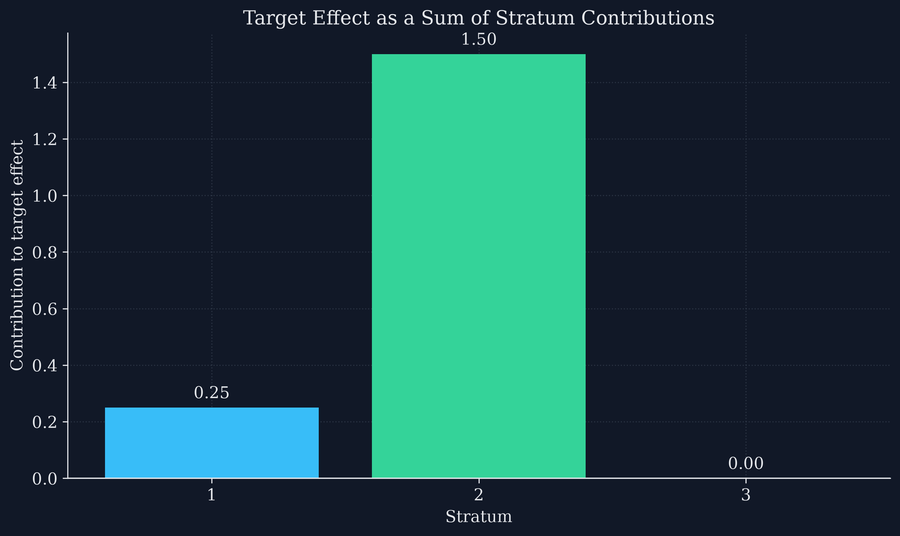

In [1]:
notation = pd.DataFrame([{'Symbol': 'S_i', 'Description': 'Population indicator: one for source and zero for target'}, {'Symbol': 'G_i', 'Description': 'Finite stratum containing unit i'}, {'Symbol': 'Y_i(a)', 'Description': 'Potential outcome for unit i under treatment level a'}, {'Symbol': 'mu_a^S(g)', 'Description': 'Source mean potential outcome under treatment a in stratum g'}, {'Symbol': 'tau^S(g)', 'Description': 'Source treatment contrast in stratum g'}, {'Symbol': 'pi_g^T', 'Description': 'Target probability of stratum g'}, {'Symbol': 'tau^T', 'Description': 'Target average treatment effect under the stated assumptions'}])
save_table(notation, 'transport_notation', 'Notation for finite-stratum transport.', 'tab:cim6-transport-notation', fit=True)
assumptions = pd.DataFrame([{'Requirement': 'Source treatment exchangeability', 'Role': 'Connects source treatment groups to source conditional potential-outcome means', 'Checked by calculation': 'Not checked'}, {'Requirement': 'Consistency', 'Role': 'Connects observed outcomes to the treatment actually received', 'Checked by calculation': 'Not checked'}, {'Requirement': 'Shared definitions', 'Role': 'Keeps treatment and outcome meanings aligned across populations', 'Checked by calculation': 'Not checked'}, {'Requirement': 'Conditional mean transportability', 'Role': 'Carries stratum-specific potential-outcome means from source to target', 'Checked by calculation': 'Not checked'}, {'Requirement': 'Source support where target probability is positive', 'Role': 'Requires both source treatment groups wherever target probability is positive', 'Checked by calculation': 'Checked'}])
save_table(assumptions, 'transport_assumption_ledger', 'Assumption ledger for finite-stratum standardization.', 'tab:cim6-transport-assumptions', fit=True)
treated_means = np.array([2.0, 4.0, 8.0])
control_means = np.array([1.0, 2.0, 9.0])
target_probabilities = np.array([0.25, 0.75, 0.0])
source_treated_counts = np.array([2.0, 4.0, 0.0])
source_control_counts = np.array([3.0, 7.0, 0.0])
stratum_effects = treated_means - control_means
contributions = target_probabilities * stratum_effects
exact_transport = transported_ate(treated_means, control_means, target_probabilities, source_treated_counts, source_control_counts)
assert np.isclose(exact_transport, 1.75)
exact_inputs = pd.DataFrame({'Stratum': [1, 2, 3], 'Treated mean': treated_means, 'Control mean': control_means, 'Stratum effect': stratum_effects, 'Target probability': target_probabilities, 'Treated source count': source_treated_counts, 'Control source count': source_control_counts})
save_table(exact_inputs, 'transport_exact_inputs', 'Inputs for the released exact standardization calculation.', 'tab:cim6-transport-exact-inputs', fit=True)
exact_contributions = exact_inputs[['Stratum', 'Stratum effect', 'Target probability']].copy()
exact_contributions['Target contribution'] = contributions
save_table(exact_contributions, 'transport_exact_contributions', 'Stratum contributions to the exact target effect.', 'tab:cim6-transport-exact-contributions')
exact_check = pd.DataFrame([{'Quantity': 'Released calculation', 'Value': exact_transport}, {'Quantity': 'Direct weighted sum', 'Value': contributions.sum()}, {'Quantity': 'Absolute difference', 'Value': abs(exact_transport - contributions.sum())}])
save_table(exact_check, 'transport_exact_check', 'Exact standardization identity check.', 'tab:cim6-transport-exact-check')
exact_contributions.to_csv(FIGURE_DATA / 'transport_exact_contributions.csv', index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
bars = axis.bar(exact_contributions['Stratum'].astype(str), exact_contributions['Target contribution'], color=[PALETTE['cyan'], PALETTE['green'], PALETTE['amber']])
axis.axhline(0, color=PALETTE['text'], linewidth=0.9, alpha=0.7)
axis.set_xlabel('Stratum')
axis.set_ylabel('Contribution to target effect')
axis.set_title('Target Effect as a Sum of Stratum Contributions')
axis.bar_label(bars, fmt='%.2f', padding=4, color=PALETTE['text'])
finish_axis(axis)
save_figure(figure, 'transport_exact_contributions')


## A Descriptive Public County Standardization

The public calculation uses one row per county. Counties at or below the median 2003 log population form the source domain, and counties above the median form the target domain. Terciles of 2003 log employment define the strata. Treatment is the panel's fixed treated-group indicator, and the outcome is the change in log employment from 2003 to 2007.

This calculation shows how standardization changes when target weights differ from source weights. It is descriptive. It does not identify a transported causal minimum-wage effect because the scientific assumptions are not established by the panel.

### Provenance of the public panel used for descriptive standardization

In [2]:
raw, counties, population_median = county_frame()
assert len(raw) == 2500 and len(counties) == 500
provenance = pd.DataFrame([{'Item': 'Public source', 'Value': "Callaway and Sant'Anna county panel"}, {'Item': 'Local file', 'Value': DATA_FILE.relative_to(BOOK_ROOT).as_posix()}, {'Item': 'File bytes', 'Value': DATA_FILE.stat().st_size}, {'Item': 'Panel rows', 'Value': len(raw)}, {'Item': 'Counties', 'Value': len(counties)}, {'Item': 'Download during execution', 'Value': 'None'}])
save_table(provenance, 'transport_public_provenance', 'Provenance of the public panel used for descriptive standardization.', 'tab:cim6-transport-public-provenance', fit=True)
domain_summary = counties.groupby('Domain', as_index=False).agg(Counties=('County identifier', 'size'), Treated=('Treatment group', 'sum'), **{'Mean baseline log population': ('Log population in 2003', 'mean'), 'Mean baseline log employment': ('Log employment in 2003', 'mean'), 'Mean employment change': ('Employment change, 2003 to 2007', 'mean')})
save_table(domain_summary, 'transport_public_domains', 'Source and target domains in the public county calculation.', 'tab:cim6-transport-public-domains', fit=True)
public_summary = transport_summary(counties, 'Stratum')
public_summary.insert(1, 'Stratum name', public_summary['Stratum'].map({0: 'Low', 1: 'Middle', 2: 'High'}))
save_table(public_summary, 'transport_public_strata', 'Source outcomes, support counts, and target weights by baseline-employment stratum.', 'tab:cim6-transport-public-strata', fit=True)
public_support_book = public_summary[['Stratum name', 'Source control count', 'Source treated count', 'Source probability', 'Target count', 'Target probability']].copy()
save_table(public_support_book, 'transport_public_support_book', 'Public support counts and population weights by stratum.', 'tab:cim6-transport-public-support-book', fit=True)
public_contrasts_book = public_summary[['Stratum name', 'Source control mean', 'Source treated mean', 'Source contrast']].copy()
save_table(public_contrasts_book, 'transport_public_contrasts_book', 'Public source means and contrasts by stratum.', 'tab:cim6-transport-public-contrasts-book')
public_target_effect = transported_ate(public_summary['Source treated mean'], public_summary['Source control mean'], public_summary['Target probability'], public_summary['Source treated count'], public_summary['Source control count'])
public_source_effect = transported_ate(public_summary['Source treated mean'], public_summary['Source control mean'], public_summary['Source probability'], public_summary['Source treated count'], public_summary['Source control count'])
source = counties[counties['Domain'] == 'Source']
target = counties[counties['Domain'] == 'Target']
source_raw_difference = source.groupby('Treatment group')['Employment change, 2003 to 2007'].mean().diff().iloc[-1]
target_raw_difference = target.groupby('Treatment group')['Employment change, 2003 to 2007'].mean().diff().iloc[-1]
public_effects = pd.DataFrame([{'Calculation': 'Source-stratum weights', 'Value': public_source_effect, 'Interpretation': 'Descriptive source standardization'}, {'Calculation': 'Target-stratum weights', 'Value': public_target_effect, 'Interpretation': 'Descriptive target standardization'}, {'Calculation': 'Raw source group difference', 'Value': source_raw_difference, 'Interpretation': 'Unadjusted source comparison'}, {'Calculation': 'Raw target group difference', 'Value': target_raw_difference, 'Interpretation': 'Unadjusted target comparison'}])
save_table(public_effects, 'transport_public_effects', 'Descriptive public source and target comparisons.', 'tab:cim6-transport-public-effects', fit=True)
weight_data = public_summary[['Stratum', 'Stratum name', 'Source probability', 'Target probability']].copy()
weight_data.to_csv(FIGURE_DATA / 'transport_public_domain_weights.csv', index=False)
positions = np.arange(len(weight_data))


,Item,Value
0,Public source,Callaway and Sant'Anna county panel
1,Local file,data/public/callaway_santanna/mpdta.csv
2,File bytes,"124,867"
3,Panel rows,"2,500"
4,Counties,500
5,Download during execution,None


,Domain,Counties,Treated,Mean baseline log population,Mean baseline log employment,Mean employment change
0,Source,250,80,2.311069,4.728749,-0.032777
1,Target,250,111,4.314749,6.868272,0.016339


,Stratum,Stratum name,Source control count,Source treated count,Source control mean,Source treated mean,Source contrast,Source probability,Target count,Target probability
0,0,Low,116,47,-0.005139,-0.02826,-0.023121,0.652,4,0.016
1,1,Middle,49,32,-0.049798,-0.11837,-0.068572,0.324,85,0.34
2,2,High,5,1,-0.018972,0.052905,0.071877,0.024,161,0.644


,Stratum name,Source control count,Source treated count,Source probability,Target count,Target probability
0,Low,116,47,0.652,4,0.016
1,Middle,49,32,0.324,85,0.34
2,High,5,1,0.024,161,0.644


,Stratum name,Source control mean,Source treated mean,Source contrast
0,Low,-0.005139,-0.02826,-0.023121
1,Middle,-0.049798,-0.11837,-0.068572
2,High,-0.018972,0.052905,0.071877


,Calculation,Value,Interpretation
0,Source-stratum weights,-0.035567,Descriptive source standardization
1,Target-stratum weights,0.022605,Descriptive target standardization
2,Raw source group difference,-0.044871,Unadjusted source comparison
3,Raw target group difference,-0.046491,Unadjusted target comparison


### Source and Target Stratum Weights

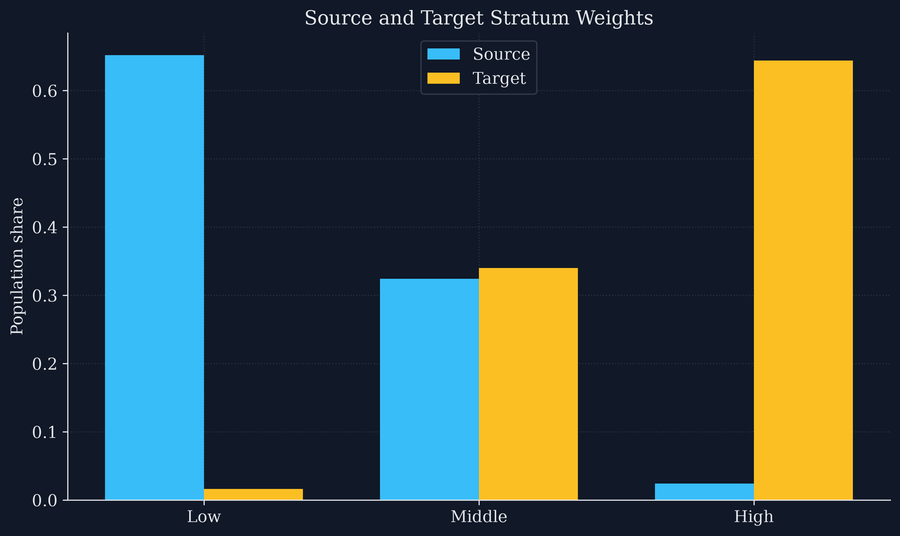

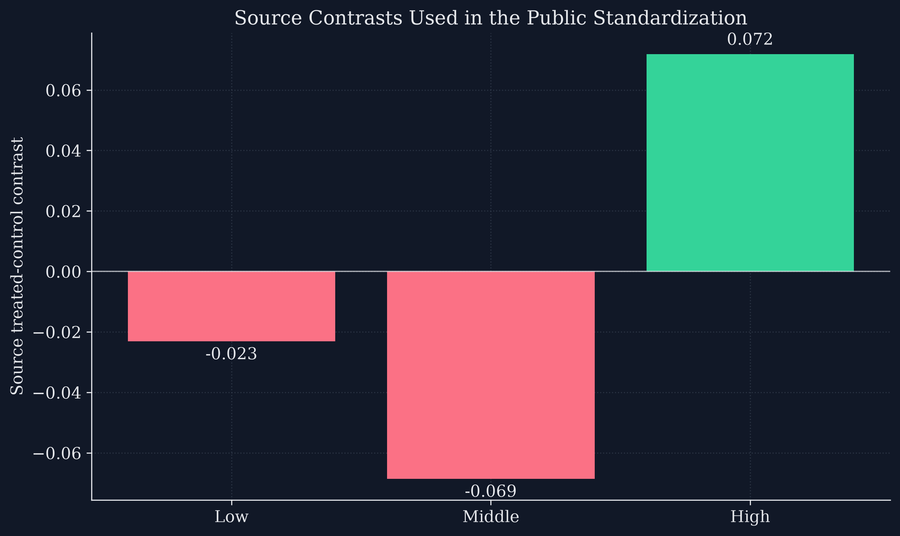

In [2]:
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
width = 0.36
axis.bar(positions - width / 2, weight_data['Source probability'], width, color=PALETTE['cyan'], label='Source')
axis.bar(positions + width / 2, weight_data['Target probability'], width, color=PALETTE['amber'], label='Target')
axis.set_xticks(positions, weight_data['Stratum name'])
axis.set_ylabel('Population share')
axis.set_title('Source and Target Stratum Weights')
axis.legend()
finish_axis(axis)
save_figure(figure, 'transport_public_domain_weights')
effect_data = public_summary[['Stratum', 'Stratum name', 'Source contrast']].copy()
effect_data.to_csv(FIGURE_DATA / 'transport_public_stratum_effects.csv', index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
colors = [PALETTE['rose'] if value < 0 else PALETTE['green'] for value in effect_data['Source contrast']]
bars = axis.bar(effect_data['Stratum name'], effect_data['Source contrast'], color=colors)
axis.axhline(0, color=PALETTE['text'], linewidth=0.9, alpha=0.7)
axis.set_ylabel('Source treated-control contrast')
axis.set_title('Source Contrasts Used in the Public Standardization')
axis.bar_label(bars, fmt='%.3f', padding=4, color=PALETTE['text'])
finish_axis(axis)
save_figure(figure, 'transport_public_stratum_effects')


## Decomposing Weight Changes

Let $\pi_g^S$ denote the source stratum share. If the same source conditional contrasts are averaged first with source weights and then with target weights, their difference is

$$
\tau^T-\tau^S=\sum_{g=1}^{K}\left(\pi_g^T-\pi_g^S\right)\tau^S(g).
$$

Here, $\tau^S$ is the source-weighted contrast and $\tau^T$ is the target-weighted contrast. Each term on the right records how the weight shift in one stratum changes the standardized value. The equality is arithmetic; a causal interpretation still requires the assumptions stated above.

### Decomposition of the public source-to-target weight change

In [3]:
decomposition = public_summary[["Stratum", "Stratum name", "Source contrast", "Source probability", "Target probability"]].copy()
decomposition["Source contribution"] = decomposition["Source probability"] * decomposition["Source contrast"]
decomposition["Target contribution"] = decomposition["Target probability"] * decomposition["Source contrast"]
decomposition["Weight-shift contribution"] = (decomposition["Target probability"] - decomposition["Source probability"]) * decomposition["Source contrast"]
save_table(decomposition, "transport_public_decomposition", "Decomposition of the public source-to-target weight change.", "tab:cim6-transport-public-decomposition", fit=True)
decomposition_book = decomposition[["Stratum name", "Source contribution", "Target contribution", "Weight-shift contribution"]].copy()
save_table(decomposition_book, "transport_public_decomposition_book", "Readable decomposition of the public source-to-target weight change.", "tab:cim6-transport-public-decomposition-book")

decomposition_check = pd.DataFrame([
    {"Quantity": "Source-weighted contrast", "Value": decomposition["Source contribution"].sum()},
    {"Quantity": "Target-weighted contrast", "Value": decomposition["Target contribution"].sum()},
    {"Quantity": "Direct difference", "Value": public_target_effect - public_source_effect},
    {"Quantity": "Sum of weight-shift contributions", "Value": decomposition["Weight-shift contribution"].sum()},
    {"Quantity": "Identity residual", "Value": (public_target_effect - public_source_effect) - decomposition["Weight-shift contribution"].sum()},
])
save_table(decomposition_check, "transport_public_decomposition_check", "Checks for the public weight-shift decomposition.", "tab:cim6-transport-public-decomposition-check")

public_boundaries = pd.DataFrame([
    {"Object": "Source conditional contrasts", "Supplied by": "Observed source group means within strata", "Does not establish": "Treatment exchangeability"},
    {"Object": "Target stratum weights", "Supplied by": "Observed target baseline distribution", "Does not establish": "Conditional effect transportability"},
    {"Object": "Target-weighted value", "Supplied by": "Finite weighted sum", "Does not establish": "A transported causal effect"},
    {"Object": "Support audit", "Supplied by": "Source counts and target weights", "Does not establish": "Substantive comparability across populations"},
])
save_table(public_boundaries, "transport_public_boundaries", "Interpretive limits of the public standardization.", "tab:cim6-transport-public-boundaries", fit=True);



,Stratum,Stratum name,Source contrast,Source probability,Target probability,Source contribution,Target contribution,Weight-shift contribution
0,0,Low,-0.023121,0.652,0.016,-0.015075,-0.00037,0.014705
1,1,Middle,-0.068572,0.324,0.34,-0.022217,-0.023314,-0.001097
2,2,High,0.071877,0.024,0.644,0.001725,0.046289,0.044564


,Stratum name,Source contribution,Target contribution,Weight-shift contribution
0,Low,-0.015075,-0.00037,0.014705
1,Middle,-0.022217,-0.023314,-0.001097
2,High,0.001725,0.046289,0.044564


,Quantity,Value
0,Source-weighted contrast,-0.035567
1,Target-weighted contrast,0.022605
2,Direct difference,0.058172
3,Sum of weight-shift contributions,0.058172
4,Identity residual,1.38778e-17


,Object,Supplied by,Does not establish
0,Source conditional contrasts,Observed source group means within strata,Treatment exchangeability
1,Target stratum weights,Observed target baseline distribution,Conditional effect transportability
2,Target-weighted value,Finite weighted sum,A transported causal effect
3,Support audit,Source counts and target weights,Substantive comparability across populations


### Changing Weights Changes Stratum Contributions

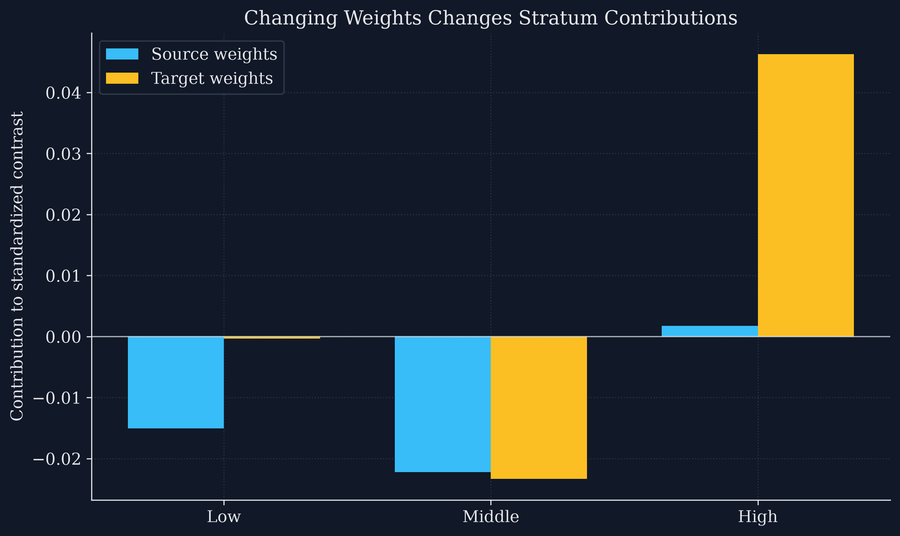

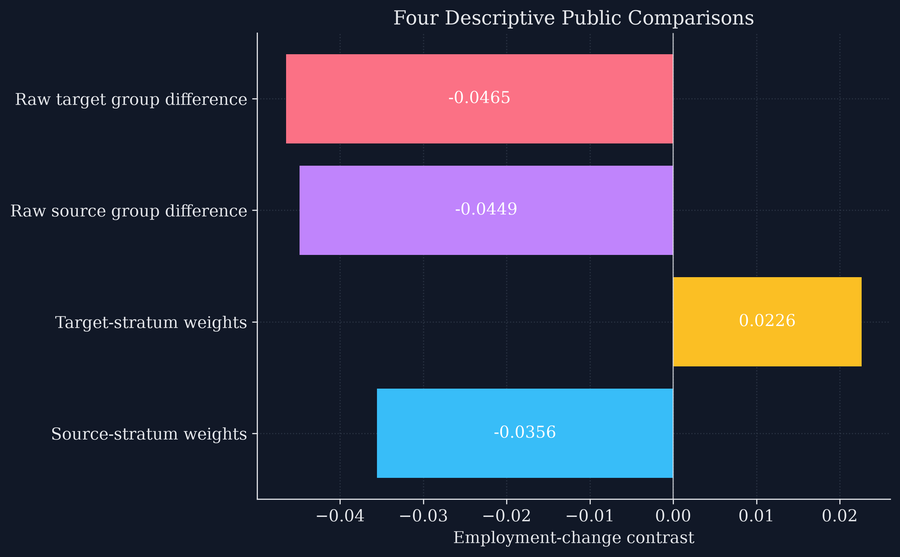

In [3]:
contribution_data = decomposition[["Stratum", "Stratum name", "Source contribution", "Target contribution"]].copy()
contribution_data.to_csv(FIGURE_DATA / "transport_public_contributions.csv", index=False)
positions = np.arange(len(contribution_data))
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
width = 0.36
axis.bar(positions - width / 2, contribution_data["Source contribution"], width, color=PALETTE["cyan"], label="Source weights")
axis.bar(positions + width / 2, contribution_data["Target contribution"], width, color=PALETTE["amber"], label="Target weights")
axis.axhline(0, color=PALETTE["text"], linewidth=0.9, alpha=0.7)
axis.set_xticks(positions, contribution_data["Stratum name"])
axis.set_ylabel("Contribution to standardized contrast")
axis.set_title("Changing Weights Changes Stratum Contributions")
axis.legend()
finish_axis(axis)
save_figure(figure, "transport_public_contributions")

comparison_data = public_effects[["Calculation", "Value"]].copy()
comparison_data.to_csv(FIGURE_DATA / "transport_public_effect_comparison.csv", index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.4), constrained_layout=True)
colors = [PALETTE["cyan"], PALETTE["amber"], PALETTE["violet"], PALETTE["rose"]]
bars = axis.barh(comparison_data["Calculation"], comparison_data["Value"], color=colors)
axis.axvline(0, color=PALETTE["text"], linewidth=0.9, alpha=0.7)
axis.set_xlabel("Employment-change contrast")
axis.set_title("Four Descriptive Public Comparisons")
axis.bar_label(bars, fmt="%.4f", label_type="center", color="white")
finish_axis(axis)
save_figure(figure, "transport_public_effect_comparison")